In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/diabetes.csv")

features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
columns_with_fake_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print(df.shape)

(768, 9)


In [22]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.dtypes.value_counts())

Duplicate rows: 0
int64      7
float64    2
Name: count, dtype: int64


In [23]:
df_clean = df.copy()

for col in columns_with_fake_zeros:
    df_clean[col] = df_clean[col].replace(0, np.nan)

print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


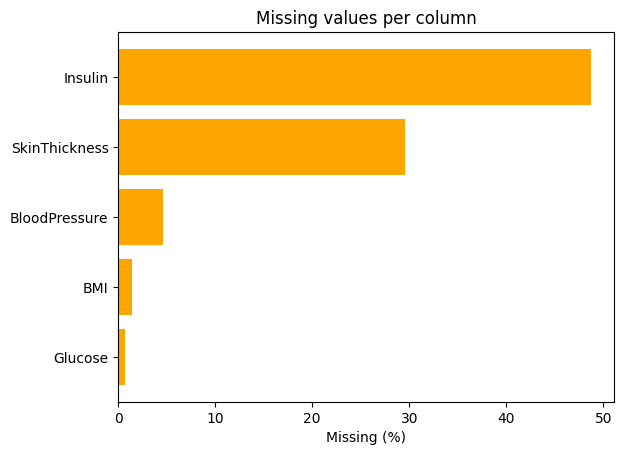

In [24]:
missing_percent = (df_clean.isnull().sum() / len(df_clean) * 100).round(1)
missing_percent = missing_percent[missing_percent > 0].sort_values()

plt.barh(missing_percent.index, missing_percent.values, color="orange")
plt.title("Missing values per column")
plt.xlabel("Missing (%)")
plt.show()

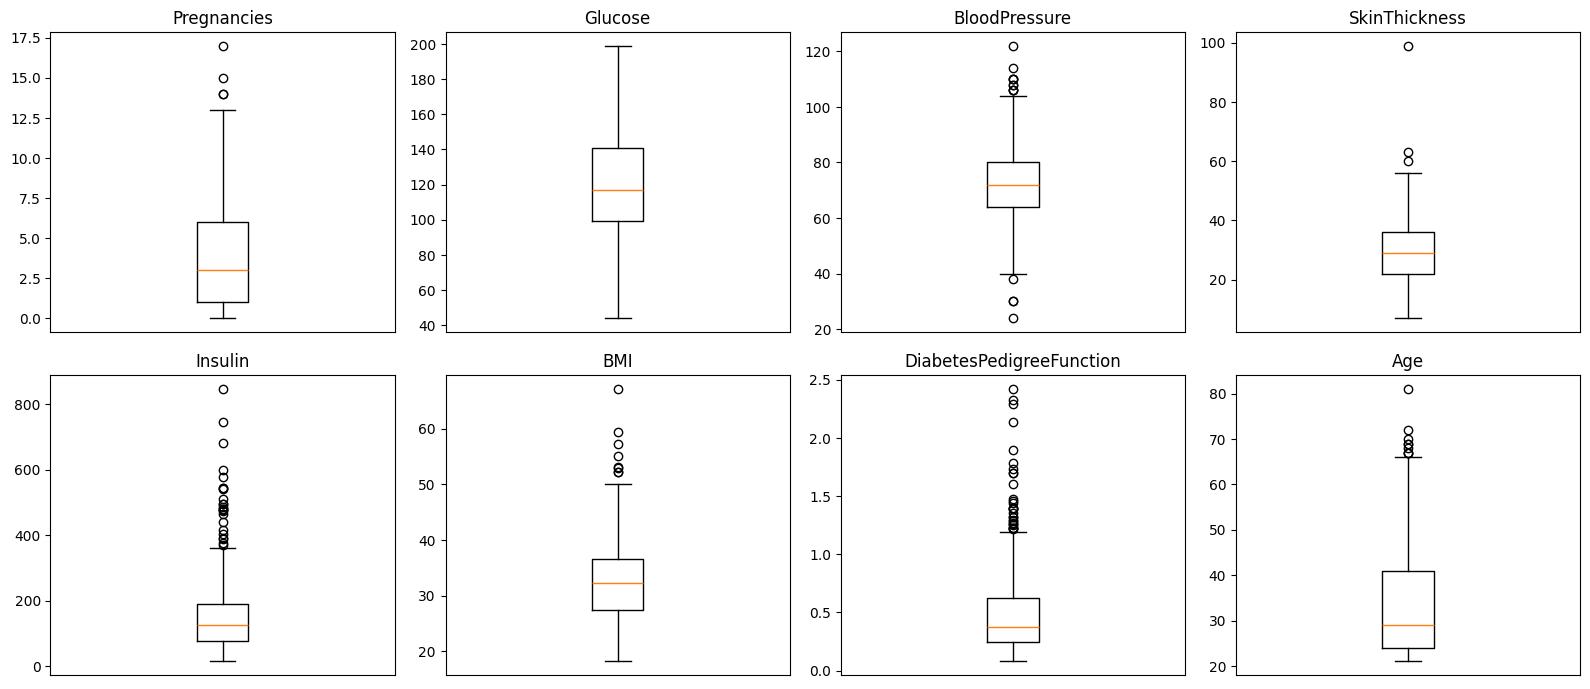

In [25]:
plt.figure(figsize=(16, 7))
for i in range(len(features)):
    plt.subplot(2, 4, i + 1)
    plt.boxplot(df_clean[features[i]].dropna())
    plt.title(features[i])
    plt.xticks([])
plt.tight_layout()
plt.show()

In [26]:
for col in features:
    values = df_clean[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((values < low) | (values > high)).sum()
    print(col, ": outliers =", count, ", max =", values.max())

Pregnancies : outliers = 4 , max = 17
Glucose : outliers = 0 , max = 199.0
BloodPressure : outliers = 14 , max = 122.0
SkinThickness : outliers = 3 , max = 99.0
Insulin : outliers = 24 , max = 846.0
BMI : outliers = 8 , max = 67.1
DiabetesPedigreeFunction : outliers = 29 , max = 2.42
Age : outliers = 9 , max = 81


In [27]:
# Decision: keep the outliers (extreme but possible values, and we can't spare rows),
# except one doubtful value: a skin thickness of 99 mm, treated as missing.
df_clean.loc[df_clean["SkinThickness"] > 90, "SkinThickness"] = np.nan

print("Missing SkinThickness:", df_clean["SkinThickness"].isnull().sum())

Missing SkinThickness: 228


In [28]:
df_clean.to_csv("../data/diabetes_clean.csv", index=False)
print("Saved cleaned data:", df_clean.shape)

Saved cleaned data: (768, 9)


In [29]:
X = df_clean[features]
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (614, 8) | Test: (154, 8)


In [30]:
imputer = SimpleImputer(strategy="median")

X_train_filled = imputer.fit_transform(X_train)   # learn the medians and fill the train
X_test_filled = imputer.transform(X_test)         # fill the test with the TRAIN medians

In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_filled)
X_test_scaled = scaler.transform(X_test_filled)

In [32]:
train_final = pd.DataFrame(X_train_scaled, columns=features, index=X_train.index)
train_final["Outcome"] = y_train

test_final = pd.DataFrame(X_test_scaled, columns=features, index=X_test.index)
test_final["Outcome"] = y_test

In [33]:
print("Missing in train:", train_final.isnull().sum().sum())
print("Missing in test: ", test_final.isnull().sum().sum())
print()
print("Train (should be mean 0, std 1):")
print(train_final[features].agg(["mean", "std"]).T.round(2))
print()
print("Test (close to 0 and 1, but not exact):")
print(test_final[features].agg(["mean", "std"]).T.round(2))

Missing in train: 0
Missing in test:  0

Train (should be mean 0, std 1):
                          mean  std
Pregnancies               -0.0  1.0
Glucose                   -0.0  1.0
BloodPressure              0.0  1.0
SkinThickness             -0.0  1.0
Insulin                   -0.0  1.0
BMI                        0.0  1.0
DiabetesPedigreeFunction  -0.0  1.0
Age                       -0.0  1.0

Test (close to 0 and 1, but not exact):
                          mean   std
Pregnancies               0.04  1.08
Glucose                  -0.00  1.07
BloodPressure             0.10  0.92
SkinThickness             0.05  1.00
Insulin                   0.19  1.41
BMI                       0.01  1.04
DiabetesPedigreeFunction -0.08  1.02
Age                      -0.05  0.97


In [34]:
train_final.to_csv("../data/train_final.csv", index=False)
test_final.to_csv("../data/test_final.csv", index=False)

joblib.dump(imputer, "../models/imputer.joblib")
joblib.dump(scaler, "../models/scaler.joblib")

print("Saved:", train_final.shape, test_final.shape)

Saved: (614, 9) (154, 9)
